# Lab 5: Nuclear Norm and Primal-Dual

Nella prima parte di questo laboratorio ci concentremo sull'implementazione e l'uso di ISTA e FISTA per problemi di ottimizzazione con trace regularization (i.e. nuclear norm). Nella seconda parte, invece, ci concentriamo su l'algoritmo di Chambolle e Pock

In [1]:
import numpy as np
from math import ceil
import matplotlib.pyplot as plt


rnd_state = np.random.RandomState(1212)

# Nuclear Norm
Il problema che affrontiamo in questo laboratorio e\` il *matrix completion* problem ovvero vogliamo recuperare una matrice $X \in \mathbb{R}^{d \times d}$ avendo a disposizione unicamente un sotto-insieme (rumoroso) delle sue entrate $y \in \mathbb{R}^s$ con $s << d^2$.

Il problema e\` formalizzabile come segue: sia $I$ un sotto-insieme di indici di cardinalita\` $s$ e definiamo l'operatore (lineare) di sampling $\Phi_I : \mathbb{R}^{d \times d} \to \mathbb{R}^s$ come segue
$$
\Phi_I X = (X_{i, j})_{(i, j) \in I}.
$$
In altre parole, data una matrice $X \in \mathbb{R}^{d \times d}$, l'operatore $\Phi_I$ costruisce un vettore le cui entrate sono le entrate della matrice $X$ indicate dal set $I$.

Di seguito, assumeremo che la matrice $X$ che vogliamo recuperare sia di rango $r << d$ (low rank). Ad esempio consideriamo il caso:
- $d = 100$.
- $r = 10$.
- $s = d r \log d$

In [2]:
d = 100
r = 10

s = ceil(d * r * np.log(d))

# genera un set di indici random (senza replacement)
I = rnd_state.permutation(d*d)
I = np.array([(idx // d, idx % d) for idx in I[:s]])#.reshape(-1, 2)

# Costruiamo una matrice di rango r come prodotto di matrici gaussiane
X_star = rnd_state.randn(d, r) @ rnd_state.randn(r, d)

print(f"[--] rank(X^*) = {np.linalg.matrix_rank(X_star)}")

[--] rank(X^*) = 10


Possiamo plottare i valori singolari computando la SVD (vedi [np.linalg.svd](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html) )

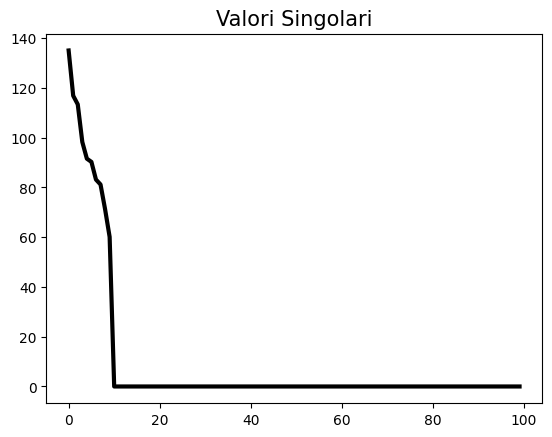

In [3]:
_, s_vals, _ = np.linalg.svd(X_star) # computiamo i valori singolari

fig, ax = plt.subplots()
ax.set_title("Valori Singolari", fontsize=15)
_ = ax.plot(s_vals, '-', lw=3, c='black')

Implementiamo una funzione `phi(X)` che data una matrice $X \in \mathbb{R}^{d \times d}$ e ritorna un vettore $\Phi_I X$ tale che
$$
\Phi_I X = (X_{i, j})_{(i, j) \in I}.
$$
Inoltre aggiungiamo del noise ottenendo
$$
y = \Phi_I X^* + \epsilon
$$
con $\epsilon \in \mathbb{R}^s$ gaussiano con standard deviation $0.1$.

In [4]:
def phi(X):
  return X[I[:, 0], I[:, 1]]

noise_std = 0.1
y = phi(X_star) + noise_std * rnd_state.randn(s) # osservazione noisy



Formalizziamo il problema di recuperare tale matrice a partire dall'osservazione noisy $y$ come segue:
$$
X^* \in \arg\min\limits_{X \in \mathbb{R}^{d \times d}} F(X) := \underbrace{\frac{1}{2} \| \Phi_I X - y \|^2}_{=:f(x)} + \underbrace{\lambda \| X \|_*}_{=: g(x)},
$$
con $\lambda > 0$ parametro di regolarizzazione che controlla la sparsita\` della soluzione e $\|\cdot \|_*$ *nuclear norm* definita come segue:
$$
\| X \|_* = \sum\limits_{i = 1}^d \sigma_i(X),
$$
con $\sigma_i(X)$ valori singolari di $X$.

In [5]:
def F(X, lam):
  # in numpy possiamo specificare la nuclear norm passando il parametro ord='nuc' a np.linalg.norm
  return 1/2 * np.square(np.linalg.norm(phi(X) - y, ord=2)) + lam * np.linalg.norm(X, ord='nuc')

Sia $X_0 \in \mathbb{R}^{d \times d}$ e $\gamma < 2/\| \Phi^* \Phi \| = 2$, consideriamo la seguente iterazione
$$
X_{k + 1} = \text{prox}_{\gamma \lambda \| \cdot \|_*}(X_k - \gamma \Phi_I^* (\Phi_I X_k - y ))
$$

Sia $I = \{ (i_c, j_c) \}_{c=1}^s \in \mathbb{R}^s$ con $1 \leq i_c,j_c \leq d$, $\Phi^*_I$ e\` l'operatore che dato un $x \in \mathbb{R}^s$, ritorna la matrice $\Phi^*_I(x)$ dove
$$
[\Phi^*_I(x)]_{i_c, j_c} = x_c
$$

Implementiamo questo operatore con la funzione `phi_star(x)` i.e. una funzione che prende in input una `x` e ritorna la matrice $\Phi^*_I(x)$.

In [6]:
def phi_star(y):
  X = np.zeros((d, d))
  X[I[:, 0], I[:, 1]] = y
  return X

Implementiamo inoltre la funzione `grad_f(x)` che presa una matrice $X \in \mathbb{R}^{d \times d}$ calcola il gradiente $\nabla f(X)$.

In [7]:
def grad_f(x):
  # TODO: ritorna il gradiente di f in x
  return phi_star((phi(x)-y))



Per calcolare il prox di della nuclear norm $\| X \|_*$ possiamo:
- calcolare la SVD di $X = U \Sigma V^\intercal$ con $\Sigma = \text{diag}(\sigma(X))$.
- calcolare il soft-thresholding di $\Sigma$ i.e.
$$
\text{prox}_{\gamma \lambda \| \cdot \|_*}(X) = U \text{prox}_{\gamma \lambda \| \cdot \|_1}(\sigma(X))V^\intercal
$$

Implementiamo quindi una funzione `prox(X, tau)` che svolge esattamente queste operazioni i.e. presa una matrice `X` e un parametro `tau`, ritorna
$$
\text{prox}_{\tau \| \cdot \|_*}(X)
$$
___
**Hint:** per calcolare la SVD in python possiamo usare [np.linalg.svd](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)
___

In [8]:
def prox(X, tau):
  # TODO: ritorna il prox della nuclear norm
  U, S, Vt= np.linalg.svd(X)
  prox=[]
  for i in range(len(S)):
    if S[i]> tau:
      prox.append(S[i]-tau)
    elif S[i]< -tau:
     prox.append(S[i]+tau)
    else:
     prox.append(0)

  return U @ np.array(np.diag(prox)) @ Vt



Definiamo ora la funzione `fb` che implementa l'algoritmo Forward-Backward. Nello specifico la funzione prendera\` i seguenti parametri
```
fb(X0, lam, gamma, T)
```
dove:
- `X0` e\` il guess iniziale.
- `lam` e\` il parametro di regolarizzazione $\lambda$.
- `gamma` e\` lo step-size $\gamma$.
- `T` e\` il numero di iterazioni.

La funzione ritorna $X_T$ (l'ultima iterata) e la sequenza $\|X_{k} - X^* \|_F$ per ogni iterata $X_k$.

In [9]:
def fb(X0, lam, gamma, T = 100):
  X = X0.copy()
  x_norms = np.zeros(T)
  x_norms[0] = np.linalg.norm(X0.copy() - X_star, ord='fro')
  f_vals = [F(X, lam)]
  for t in range(1, T):
    # TODO: implementa l'iterazione di Forward-Backward
    X = prox(X-gamma*grad_f(X),gamma*lam)
    x_norms[t] = np.linalg.norm(X.copy() - X_star, ord='fro')
    f_vals.append(F(X, lam))

  return X, x_norms, f_vals




eseguiamo l'algoritmo con stepsize $\gamma = 1.0$ e $\lambda = 0.1$.

In [10]:
gamma = 1.9
lam = 0.1
x0 = np.full((d, d), 10.0)

T = 3000

# TODO: esegui Forward-backward
X, x_norms, f_vals = fb(x0, lam, gamma, T)

Plottiamo il risultato ottenuto

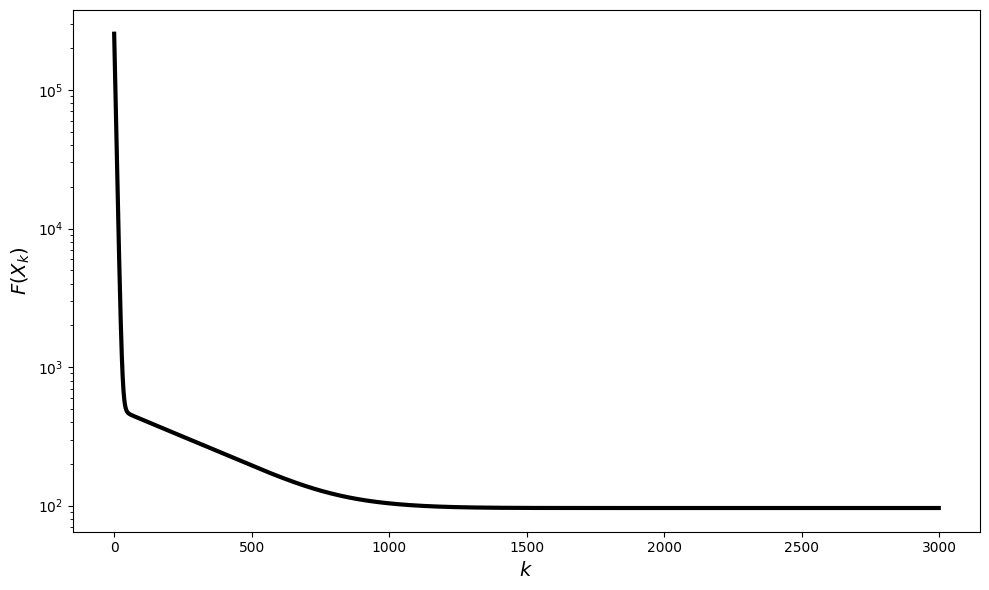

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
ax.plot(range(len(f_vals)), f_vals, '-', c='black', lw=3)

ax.set_xlabel("$k$", fontsize=14)
ax.set_yscale("log")
ax.set_ylabel("$F(X_k)$", fontsize=14)
fig.tight_layout()

####Al variare di gamma

In [12]:
gamma_values = [0.5, 1, 1.5, 1.9]
lam = 0.1
x0 = np.full((d, d), 10.0)
T = 3000

# Run forward-backward for each gamma value
results = []
for gamma in gamma_values:
    X, x_norms, f_vals = fb(x0, lam, gamma, T)
    results.append((X, x_norms, f_vals))


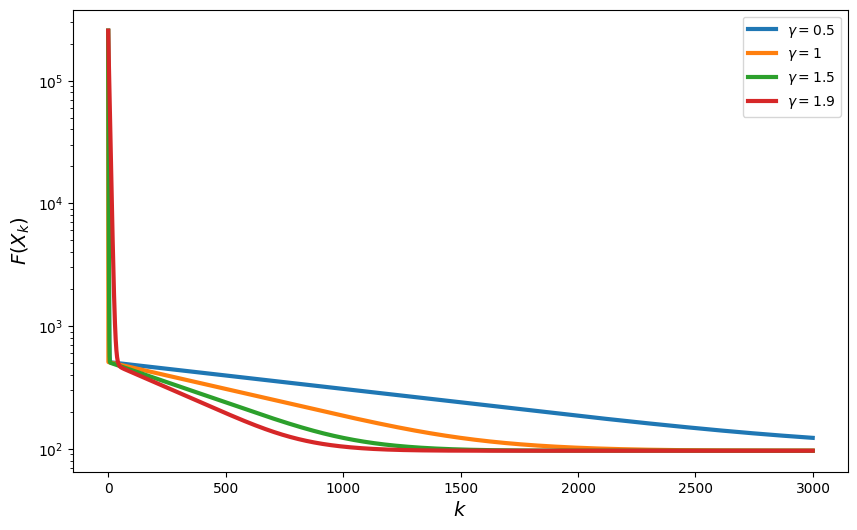

In [13]:
# Plot the results
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

for gamma, (X, x_norms, f_vals) in zip(gamma_values, results):
    ax.plot(range(len(f_vals)), f_vals, '-', lw=3, label=f"$\gamma = {gamma}$")

ax.set_yscale("log")
ax.set_xlabel("$k$", fontsize=14)
ax.set_ylabel("$F(X_k)$", fontsize=14)
ax.legend()
plt.show()


## FISTA
Come nei precedenti laboratori, possiamo estendere l'algoritmo includendo un termine d'inerzia.

Implementiamo quindi la funzione
```
fista(X0, lam, gamma, T)
```
dove:
- `X0` e\` il guess iniziale.
- `lam` e\` il parametro di regolarizzazione $\lambda$.
- `gamma` e\` lo step-size $\gamma$.
- `T` e\` il numero di iterazioni.

Come la funzione precedente, deve ritornare:
- `X` l'ultima iterata.
- `x_norms` la sequenza $\|X_{k} - X^* \|_F$ per ogni iterata $X_k$.

In [14]:
def fista(X0, lam, gamma, alpha, T = 100):
  X = X0.copy()
  x_norms = np.zeros(T)
  x_norms[0] = np.linalg.norm(X0.copy() - X_star, ord='fro')
  f_vals = [F(X, lam)]
  tk = 1
  Y = X.copy()
  for k in range(1, T):
    # TODO: calcola il parametro d'inerzia
    tk_next = (k+alpha)/alpha
    beta = (tk-1)/tk_next
    # TODO: implementa l'iterazione di FISTA
    X_next = prox(Y-gamma*grad_f(Y), gamma*lam)
    Y_next =  X_next+beta*(X_next-X)

    f_vals.append(F(X_next, lam))
    x_norms[k] = np.linalg.norm(X.copy() - X_star, ord='fro')
    X = X_next
    Y = Y_next
    tk = tk_next

  return X, x_norms, f_vals


Eseguiamo FISTA con gli stessi parametri di ISTA (stepsize e $\lambda$)

In [15]:
# TODO: esegui FISTA
X_fist, x_fista_norms, f_fista_vals = fista(x0, lam=0.1, gamma=1, alpha=2, T = 3000)

Confrontiamo ora il risultato ottenuto da FISTA con quello ottenuto da ISTA

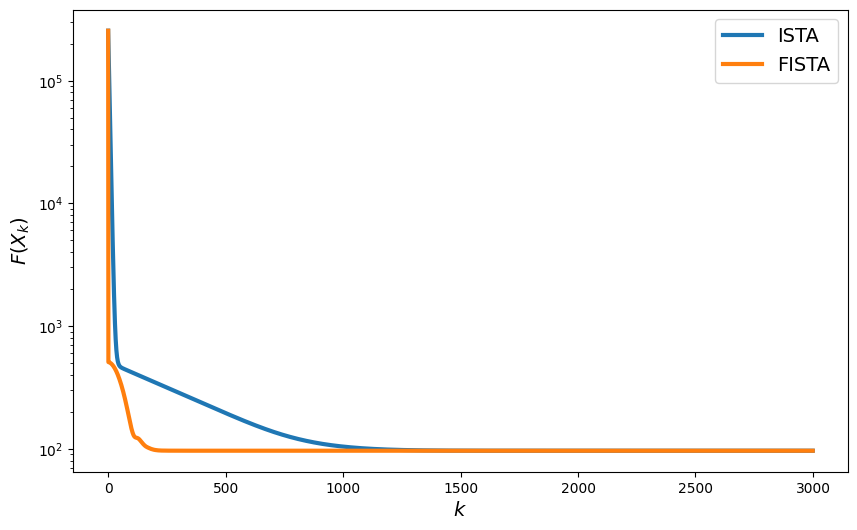

In [16]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

ax.plot(range(len(f_vals)), f_vals, '-', lw=3, label='ISTA')
ax.plot(range(len(f_fista_vals)), f_fista_vals, '-', lw=3, label='FISTA')

ax.set_xlabel("$k$", fontsize=14)
ax.set_ylabel("$F(X_k)$", fontsize=14)
ax.set_yscale("log")
ax.legend(fontsize=14)

####al variare di alpha

In [17]:
import matplotlib.pyplot as plt

# Define a function to run FISTA for given alpha
def run_fista(alpha):
    X_fist, x_fista_norms, f_fista_vals = fista(x0, lam=0.1, gamma=1, alpha=alpha, T=3000)
    return f_fista_vals

# Define alphas
alphas = [2, 5, 12]

# Run FISTA for each alpha and store the results
fista_results = {alpha: run_fista(alpha) for alpha in alphas}



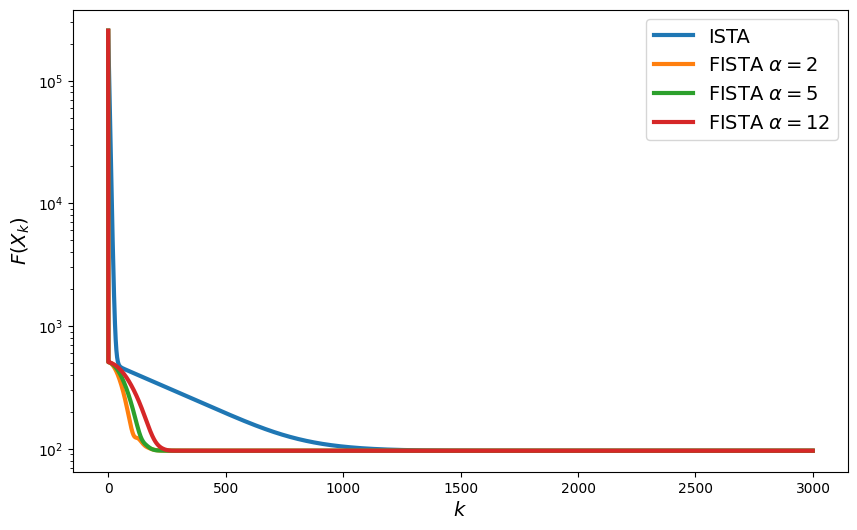

In [18]:
# Plotting
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

# Plot ISTA curve
ax.plot(range(len(f_vals)), f_vals, '-', lw=3, label='ISTA')

# Plot FISTA curves for different alphas
for alpha in alphas:
    ax.plot(range(len(fista_results[alpha])), fista_results[alpha], '-', lw=3, label=f"FISTA $\\alpha = {alpha}$")

ax.set_xlabel("$k$", fontsize=14)
ax.set_ylabel("$F(X_k)$", fontsize=14)
ax.set_yscale("log")
ax.legend(fontsize=14)

plt.show()

## Gradient Descent sul Duale
Un metodo alternativo per risolvere il problema consiste nell'approsimare $X^*$ risolvendo il seguente problema
$$
\min\limits_{\Phi_I X = y} \| X \|_* + 1/3 \| X \|_F^2
$$
Nello specifico, possiamo risolvere il problema con gradient descent nel problema duale i.e. sia $u_0 = y$
$$
x_k = \text{prox}_{\|.\|_*/0.33}(-3 \Phi_I^* u_k)\\
u_{k+1} = u_k + \gamma (\Phi_I(X_k) - y)
$$
con $\gamma < 2/\|\Phi_I \Phi_I^* \| = 2$.

Definiamo quindi la funzione `dual_gd` che implementa l'iterazione proposta.


Tale funzione prende in input $x_0$, $\gamma$ e un numero di iterazioni $T$ e ritorna $x_T$ e le sequenze $\|x_k - x^*\|, \| \Phi x_k - y \|^2$

In [19]:
def dual_gd(x0, gamma, T = 100):
  x = x0.copy()
  u = y.copy()
  x_norms = [np.linalg.norm(X0.copy() - X_star, ord='fro')]
  phi_norms = [np.square(np.linalg.norm(phi(x) - y))]

  for k in range(T):

    # TODO: implementa prox-gradient per il problema duale
    x = prox(-3*phi_star(u),1/3)
    u = u+gamma*(phi(x)-y)

    x_norms.append(np.linalg.norm(x.copy() - X_star,ord='fro'))
    phi_norms.append(np.square(np.linalg.norm(phi(x) - y)))
  return x, x_norms, phi_norms

Per testare l'algoritmo, consideriamo il matrix completition problem introdotto precedetemente con $d = 500$, rango $r = 100$ e numero di osservazioni $s = 5$.

In [20]:
d = 10
r = 10

s =50

I = rnd_state.permutation(d*d)
I = np.array([(idx // d, idx % d) for idx in I[:s]])

X_star = rnd_state.randn(d, r) @ rnd_state.randn(r, d)

# Consideriamo un noise piu` alto
noise_std = 6.00
y = phi(X_star) + noise_std * rnd_state.randn(s) # osservazione noisy


print(f"[--] rank(X^*) = {np.linalg.matrix_rank(X_star)}")
gamma = 1/3
X0 = np.full((d, d), 1300)

T = 12

# TODO: esegui dual gd
X_dgd, x_dgd_norms, phi_norms = dual_gd(X0, gamma, T)

[--] rank(X^*) = 10


Plottiamo i risultati ottenuti

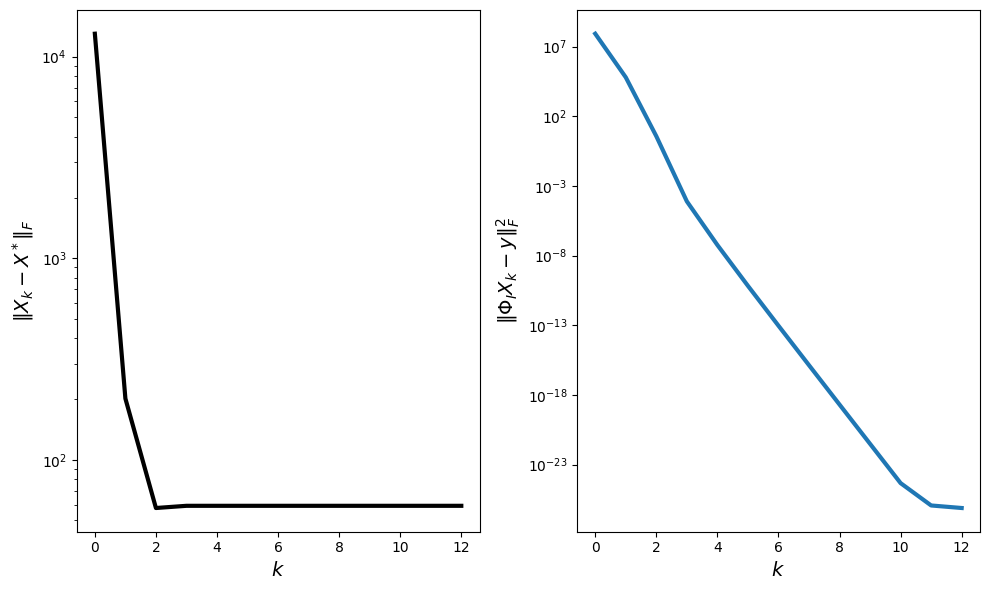

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6))
ax1.plot(range(len(x_dgd_norms)), x_dgd_norms, '-', c='black', lw=3)
ax2.plot(range(len(phi_norms)), phi_norms, '-', lw=3)

ax1.set_xlabel("$k$", fontsize=14)
ax1.set_ylabel("$\| X_k - X^* \|_F$", fontsize=14)
ax1.set_yscale("log")

ax2.set_xlabel("$k$", fontsize=14)
ax2.set_ylabel("$\| \Phi_I X_k - y \|_F^2$", fontsize=14)
ax2.set_yscale("log")

fig.tight_layout()



si regolarizza troppo quindi sale


# Primal-Dual: Chambolle-Pock
Consideriamo ora il seguente problema di ottimizzazione
$$
\min\limits_{x in \mathbb{R}^d} f(K x) + g(x)
$$
dove:
- $K$ e\` un operatore lineare
- $f, g$ functioni convesse, l.s.c e prossimabili

Consideriamo la primal-dual formulation
$$
\min\limits_{x \in \mathbb{R}^d} \max\limits_{y \in \mathbb{R}^d} <Kx, y> + g(x) - f^*(y)
$$

dove $f^*$ e` la coniugata di $f$. In questo problema vogliamo trovare un punto di sella $(x^*, y^*)$ tale che
$$
\left\{
  \begin{array}{l}
  Kx^* \in \partial f^*(y^*) \\
  -(K^* y^*) \in \partial g(x^*) \\
\end{array}
\right.
$$

L'algoritmo primal-dual, sotto appropriate assunzioni, permette di risolvere il problema.  L'iterazione che considereremo e` la seguente
$$
\left\{\begin{array}{l}
y_{k + 1} = \text{prox}_{\sigma F^*} (y_k + \sigma K \bar{x}_k)\\
x_{k + 1} = \text{prox}_{\tau G} (x_k - \tau K^* y_{k + 1})\\
\bar{x}_{k + 1} = x_{k + 1} + \theta (x_{k + 1} - x_k)
\end{array}
\right.
$$
Dato un initial guess $(x_0, y_0)$, scegliendo $\bar{x}_0 = x_0$ e con $\theta \in [0, 1]$


## Convex Quadratic Problem
Per comprendere il funzionamento dell'algoritmo, consideriamo il seguente problema di ottimizzazione
$$
\min\limits_{x \in \mathbb{R}^d} \underbrace{\frac{1}{2 \beta} \| Ax - b \|^2_2}_{=:F(x)} + \underbrace{\frac{\alpha}{2} \| x \|^2_2}_{=: G(x)}
$$
Con:
- $A \in \mathbb{R}^{n \times m}$, $n < m$
- $b \in \mathbb{R}^n$



In [22]:
n = 10
m = 200
beta = 1.0
alpha = 0.15

A = rnd_state.randn(n, m)
b = rnd_state.randn(n)

def F(x):
  return (1 / (2*beta)) * np.square(np.linalg.norm(A @ x - b, ord=2))

def G(x):
  return (alpha / 2) * np.square(np.linalg.norm(x, ord=2))

def target(x):
  return F(x) + G(x)


Nota che in questo esempio, possiamo calcolare esattamente la soluzione del problema primale
$$
x^* = \Bigg( \alpha I + \frac{1}{\beta} A^\intercal A \Bigg)^{-1} \Bigg(\frac{1}{\beta} A^\intercal b \Bigg) = A^\intercal (\alpha \beta I + A A^\intercal)^{-1} b .
$$

In [23]:
x_star = A.T @ np.linalg.inv(alpha * beta * np.eye(n) + A @ A.T) @ b
print("[--] F(x^*) = {}".format(target(x_star)))

[--] F(x^*) = 0.002888973232832542



Osservando che la coniugata di Fenchel di F e\`
$$
F^*(y) = \frac{\beta}{2} \|y\|^2 + <y, b>
$$


In [24]:
def fstar(y):
  return (beta / 2) * np.square(np.linalg.norm(y, ord=2)) + y.dot(b)

Possiamo riformulare il problema come segue
$$
\min\limits_{x} \max\limits_{y} \frac{\alpha}{2} \| x \|^2_2 + <Ax, b> - \frac{\beta}{2} \|y\|^2 - <y, b>
$$

Implementiamo quindi l'algoritmo primal-dual per risolvere il problema.

Iniziamo implementando due funzioni `prox_g(x, tau)` e `prox_fstar(y, sigma)` che ritornano rispettivamente il prox di $G$ in $x$ e il prox di $F^*$ in $y$. Nota che i due prox sono calcolabili in forma chiusa
$$
\text{prox}_{\tau G}(x) = \frac{x}{1 + \tau \alpha} \qquad \text{prox}_{\sigma F^*}(y) = \frac{y - \sigma b}{1 + \sigma \beta}
$$

In [25]:
def prox_g(x, tau):
  # TODO: ritorna il prox di G in x
  return x/(1+tau*alpha)

def prox_fstar(y, sigma):
  # TODO: ritorna il prox di F^* in y
  return (y-sigma*b)/(1+sigma*beta)

Ora implementiamo l'algoritmo Primal-dual. Nello specifico implementiamo una funzione `cb1` che prende in input:
- il guess iniziale $(x_0, y_0)$
- gli stepsizes $\tau$ e $\sigma$
- $\theta$
- il numero di iterazioni $T$

e ritorna:
- la soluzione $(x, y)$
- la sequenza $\|x_k - x^*\|$
- il primal dual gap

In [26]:
def compute_pd_gap(x, y):
  return F(x) + G(x) + fstar(y) + (1/(2 * alpha)) * np.square(np.linalg.norm(-A.T @ y, ord=2))

def cb1(x0, y0, tau, sigma, theta, T = 100):
  x = x_bar = x0.copy()
  y = y0.copy()
  norms = np.empty(T)
  pd_gaps = np.empty(T)
  norms[0] = np.linalg.norm(x - x_star, ord=2)
  pd_gaps[0] = compute_pd_gap(x, y)
  for t in range(1, T):
    # TODO: implementa il dual step
    y = prox_fstar(y+sigma*A @ x_bar, sigma)
    # TODO: implementa il primal step
    x_next = prox_g(x-tau*A.T @ y, tau)
    # TODO: aggiorna x_bar
    x_bar = x_next+ theta*(x_next-x)

    x = x_next
    norms[t] = np.linalg.norm(x - x_star, ord=2)
    pd_gaps[t] = compute_pd_gap(x, y)
  return (x, y), norms, pd_gaps


Come abbiamo visto in classe, se $\theta = 1$ e  $\tau \sigma \| A \|^2 \leq 1$, l'algoritmo converge con un rate di $\mathcal{O}(1/k)$.

Scegliamo quindi $\theta = 1$ e fissiamo $\tau$ e $\sigma$ tale che $\tau \sigma \| A \|^2 \leq 1$

In [27]:
print(np.linalg.norm(A)**2)
print(np.linalg.norm(A,ord=2)**2)

2001.4545960082578
308.46288686716065


In [28]:
x0 = np.ones(m)
y0 = b.copy()
theta = 1.0


# TODO: scegli dei valori appropriati per tau e sigma

tau= 0.05
sigma = 1/(tau*pow(np.linalg.norm(A, ord=2),2))

#tau = 1/np.linalg.norm(A, ord=2)
#sigma = 1/np.linalg.norm(A,ord=2)

#sigma = 0.05
#tau = 1/(sigma*pow(np.linalg.norm(A, ord=2),2))

sigma_exp = "{:e}".format(sigma)
print("[--] tau sigma ||A||^2 <= 1 ? ", tau * sigma * (np.linalg.norm(A, ord=2)**2) <= 1.0)


# TODO: esegui l'algoritmo
(x, y), norms_1, pd_gap = cb1(x0, y0, tau, sigma, theta, T=2000) #se scende tanto con meno iteraioni meglio


[--] tau sigma ||A||^2 <= 1 ?  True


Plottiamo adesso la sequenza $\| x_k - x^* \|$ e il primal dual gap

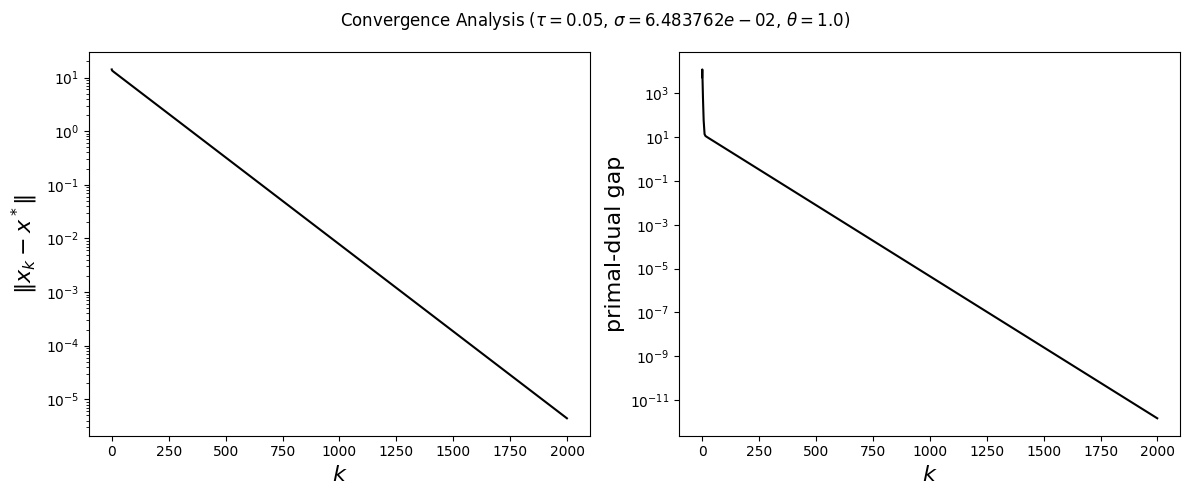

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(range(norms_1.shape[0]), norms_1, '-', c = 'black')
ax2.plot(range(pd_gap.shape[0]), pd_gap, '-', c = 'black')

ax1.set_yscale("log")
ax1.set_xlabel("$k$", fontsize=16)
ax1.set_ylabel("$\| x_k - x^* \|$", fontsize=16)

ax2.set_yscale("log")
ax2.set_xlabel("$k$", fontsize=16)
ax2.set_ylabel("primal-dual gap", fontsize=16)
plt.suptitle(r"Convergence Analysis ($\tau = $" + f"{tau}, $\sigma = {sigma_exp}$, $\\theta = {theta}$)")

fig.tight_layout()

Il risultato di convergenza previa menzionato, e\` stato successivamente esteso per $\theta > 1/2$ e
$$
\tau \sigma \| A \|^2 < \frac{4}{1 + 2 \theta}
$$
Ripetiamo quindi l'esperimento scegliendo i parametri in modo che le condizioni siano soddisfatte

In [30]:
x0 = np.ones(m)
y0 = b.copy()


# TODO: scegli dei valori appropriati per tau, sigma e theta
theta = 3/5

#NO
#tau = 1/np.linalg.norm(A, ord=2)
#sigma = 1/np.linalg.norm(A,ord=2)
#1e-1

#tau=5
tau = 0.5 #0.5 1e-16 #5 1e-16 70it
sigma=(1+2*theta)/(4*tau*pow(np.linalg.norm(A,ord=2),2))

#tau=10
#sigma=4/((2+2*theta)*tau*pow(np.linalg.norm(A,ord=2),2))
sigma_exp = "{:e}".format(sigma)

print("[--] tau sigma ||A||^2 < 4 / (1 + 2 theta) ? ", tau * sigma * ( np.linalg.norm(A, ord=2)**2) < 4 / (1 + 2 * theta))

# TODO: esegui l'algoritmo
(x, y), norms_1, pd_gap =cb1(x0, y0, tau, sigma, theta, T=300)


[--] tau sigma ||A||^2 < 4 / (1 + 2 theta) ?  True


Plottiamo quindi $\|x_k - x^*\|$ e il primal dual gap

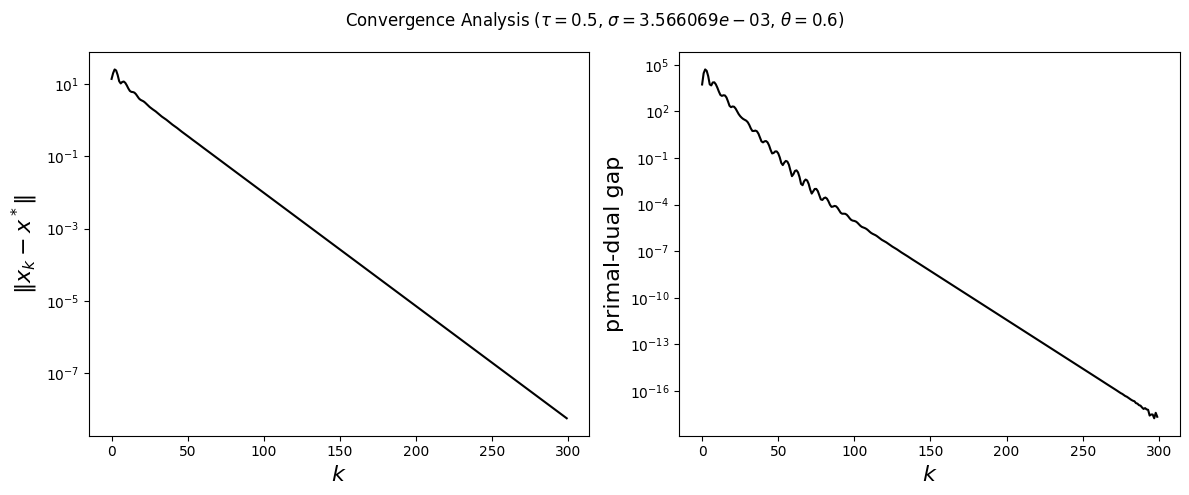

In [31]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(range(norms_1.shape[0]), norms_1, '-', c = 'black')
ax2.plot(range(pd_gap.shape[0]), pd_gap, '-', c = 'black')

ax1.set_yscale("log")
ax1.set_xlabel("$k$", fontsize=16)
ax1.set_ylabel("$\| x_k - x^* \|$", fontsize=16)

ax2.set_yscale("log")
ax2.set_xlabel("$k$", fontsize=16)
ax2.set_ylabel("primal-dual gap", fontsize=16)
plt.suptitle(r"Convergence Analysis ($\tau = $" + f"{tau}, $\sigma = {sigma_exp}$, $\\theta = {theta}$)")

fig.tight_layout()

## [Opzionale] Nuclear norm

Riprendiamo lo stesso setting visto nell'esercizio 1 e consideriamo il seguente problema di matrix completition:
$$
X^* \in \arg\min\limits_{X \in \mathbb{R}^{d \times d}} F(X) := \| X \|_*, \qquad \text{subject to} \qquad  \Phi_I X = y
$$


In [32]:
d = 100
r = 10

s = ceil(d * r * np.log(d))

I = rnd_state.permutation(d*d)
I = np.array([(idx // d, idx % d) for idx in I[:s]])#.reshape(-1, 2)

X_star = rnd_state.randn(d, r) @ rnd_state.randn(r, d)
def phi(X):
  return X[I[:, 0], I[:, 1]]

noise_std = 0.1
y = phi(X_star) + noise_std * rnd_state.randn(s) # osservazione noisy

